# Create a table of data using Les Tricoteuses as Source

## Useful Links

- API Doc : https://parlement.tricoteuses.fr/docs#tag/acteurs/GET/v2/acteurs

# Retrieve Deputy data

## List of Deputy

In [2]:
import requests
import pandas as pd

response = requests.get(
    "https://parlement.tricoteuses.fr/v2/acteurs/",
        params={
          "searchScope": "name",
            "chambre" : "AN",
            "page" : "1",
            "actif" : "true",
            "perPage" : "1000",
        }
)

data = response.json()

#response from the API with name of former deputy now minister

tricoteuse_dep_raw = pd.json_normalize(data['data'])

print(tricoteuse_dep_raw.head())

      uid        nom   prenom civ chambre  actif  \
0  PA1008      David    Alain  M.      AN   True   
1  PA1327  Forissier  Nicolas  M.      AN   True   
2  PA1567      Guedj   Jérôme  M.      AN   True   
3  PA1592      Habib    David  M.      AN   True   
4  PA1630  Herbillon   Michel  M.      AN   True   

                                            urlImage  \
0  https://tricoteuses-assets.s3.fr-par.scw.cloud...   
1  https://tricoteuses-assets.s3.fr-par.scw.cloud...   
2  https://tricoteuses-assets.s3.fr-par.scw.cloud...   
3  https://tricoteuses-assets.s3.fr-par.scw.cloud...   
4  https://tricoteuses-assets.s3.fr-par.scw.cloud...   

                                            interets placeHemicycle  \
0  [{'categorie': 'ruralite', 'label': 'Ruralité ...            410   
1  [{'categorie': 'ruralite', 'label': 'Ruralité ...            NaN   
2  [{'categorie': 'social', 'label': 'Protection ...            417   
3  [{'categorie': 'ruralite', 'label': 'Ruralité ...            45

In [3]:
#Filtering the dataframe with circonscription.uid non-null values to get only active deputies
tricoteuse_dep = tricoteuse_dep_raw[tricoteuse_dep_raw['circonscription.uid'].notnull()].drop([
    'urlImage', 
    'interets',
    'chambre',
    'placeHemicycle',
    'mandatPrincipal.uid',
    'mandatPrincipal.actif',
    'mandatPrincipal.dateDebut',
    'mandatPrincipal.dateFin',
    'mandatPrincipal.libQualite',
    'mandatPrincipal.codeQualite',
    'mandatPrincipal.libelle',
    'commissionPermanente',
    'commissionPermanente.uid',
    'commissionPermanente.libelle',
    'commissionPermanente.libelleAbrege',
    'groupeParlementaire',
    'circonscription'
    ], axis=1)

In [4]:
tricoteuse_dep.info()

<class 'pandas.DataFrame'>
Index: 574 entries, 0 to 595
Data columns (total 16 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   uid                                  574 non-null    str    
 1   nom                                  574 non-null    str    
 2   prenom                               574 non-null    str    
 3   civ                                  574 non-null    str    
 4   actif                                574 non-null    bool   
 5   compteTwitter                        357 non-null    str    
 6   compteBluesky                        178 non-null    str    
 7   groupeParlementaire.uid              574 non-null    str    
 8   groupeParlementaire.libelle          574 non-null    str    
 9   groupeParlementaire.libelleAbrege    574 non-null    str    
 10  groupeParlementaire.couleurAssociee  574 non-null    str    
 11  groupeParlementaire.chambre          574 non-nul

In [5]:
tricoteuse_dep.head()

,uid,nom,prenom,civ,actif,compteTwitter,compteBluesky,groupeParlementaire.uid,groupeParlementaire.libelle,groupeParlementaire.libelleAbrege,groupeParlementaire.couleurAssociee,groupeParlementaire.chambre,circonscription.uid,circonscription.numCirco,circonscription.numDepartement,circonscription.libelle
0,PA1008,David,Alain,M.,True,NaN,alaindavid.bsky.social,PO845419,Socialistes et apparentés,SOC,#EC407A,AN,PO839429,4.0,33.0,4ème circonscription de la Gironde
2,PA1567,Guedj,Jérôme,M.,True,@JeromeGuedj,NaN,PO845419,Socialistes et apparentés,SOC,#EC407A,AN,PO839989,6.0,91.0,6ème circonscription de l'Essonne
3,PA1592,Habib,David,M.,True,@DavidDhabib,wrenswatch.bsky.social,PO845485,"Libertés, Indépendants, Outre-mer et Territoires",LIOT,#CBA603,AN,PO839701,3.0,64.0,3ème circonscription des Pyrénées-Atlantiques
4,PA1630,Herbillon,Michel,M.,True,@Michelherbillon,NaN,PO845425,Droite Républicaine,DR,#15A2A2,AN,PO838957,8.0,94.0,8ème circonscription du Val-de-Marne
5,PA1654,Hollande,François,M.,True,NaN,fhollande.bsky.social,PO845419,Socialistes et apparentés,SOC,#EC407A,AN,PO839227,1.0,19.0,1ère circonscription de la Corrèze


# Retrieve Mails Data

After first analysis, the table sent by "https://parlement.tricoteuses.fr/adressesElectroniques/json" contains not only email adress but also Phone numbers and Adress of Websites.

Next Step : Add mail, Webesite adress to deputy table

## Download from API and Data Exploration

In [6]:
response_mail = requests.get(
    "https://parlement.tricoteuses.fr/adressesElectroniques/json",
        params={
            "page" : "1",
            "perPage" : "10000",
        }   
)

response_mail_data = response_mail.json()
mail_df = pd.json_normalize(response_mail_data['data'])
mail_df.head()

,uid,dataset,type,typeLibelle,poids,adresseDeRattachement,valElec,xsiType,acteurRefUid,dateMaj,datePremierAjout
0,AD395657,0,11,Téléphone,1,AD386857,01 40 63 75 53,AdresseTelephonique_Type,PA1001,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
1,AD395658,0,12,Télécopie,1,AD386857,01 40 63 79 37,AdresseTelephonique_Type,PA1001,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
2,AD716041,0,15,Mèl,NaN,NaN,bastruc@ville-lambersart.fr,AdresseMail_Type,PA1001,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
3,AD716070,0,15,Mèl,NaN,NaN,mdp.contact@yahoo.fr,AdresseMail_Type,PA1001,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
4,AD716102,0,15,Mèl,NaN,NaN,mpdaubresse@assemblee-nationale.fr,AdresseMail_Type,PA1001,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z


In [7]:
mail_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7630 entries, 0 to 7629
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   uid                    7630 non-null   str  
 1   dataset                7630 non-null   int64
 2   type                   7630 non-null   str  
 3   typeLibelle            7630 non-null   str  
 4   poids                  864 non-null    str  
 5   adresseDeRattachement  863 non-null    str  
 6   valElec                7629 non-null   str  
 7   xsiType                7630 non-null   str  
 8   acteurRefUid           7630 non-null   str  
 9   dateMaj                7630 non-null   str  
 10  datePremierAjout       7630 non-null   str  
dtypes: int64(1), str(10)
memory usage: 1.5 MB


In [8]:
mail_df['xsiType'].unique()

<ArrowStringArray>
['AdresseTelephonique_Type', 'AdresseMail_Type', 'AdresseSiteWeb_Type']
Length: 3, dtype: str

xsiType is category to regroup different kind of contact chanel

In [93]:
mail_df.groupby(['typeLibelle','xsiType'])['uid'].count()

typeLibelle     xsiType                 
Contact presse  AdresseTelephonique_Type       1
Facebook        AdresseSiteWeb_Type          682
Instagram       AdresseSiteWeb_Type          330
Linkedin        AdresseSiteWeb_Type          180
Mèl             AdresseMail_Type            3105
Site internet   AdresseSiteWeb_Type          700
Twitter         AdresseSiteWeb_Type          708
Télécopie       AdresseTelephonique_Type     124
Téléphone       AdresseTelephonique_Type     750
Url sénateur    AdresseSiteWeb_Type         1050
Name: uid, dtype: int64

### visualize libelle type breakdown

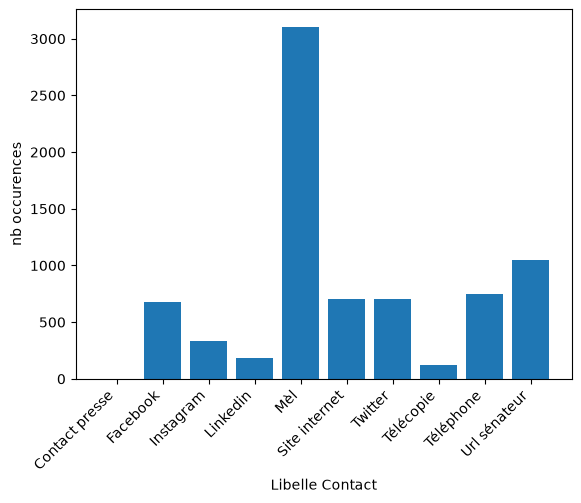

In [89]:
import matplotlib.pyplot as plt
#group by typeLybelle
plot_df = mail_df.groupby('typeLibelle').size().to_frame(name='count').reset_index()
categories = plot_df['typeLibelle']
values = plot_df['count']

plt.bar(categories, values)
plt.xlabel('Libelle Contact')
plt.ylabel('nb occurences')
plt.tick_params("x", rotation = 45, rotation_mode = "xtick")


plt.show()


### Filter mail table with active deputy uid and visualize libelle type breakdown

In [100]:
#using isin
mail_act_df = mail_df.loc[mail_df['acteurRefUid'].isin(tricoteuse_dep['uid']),:]

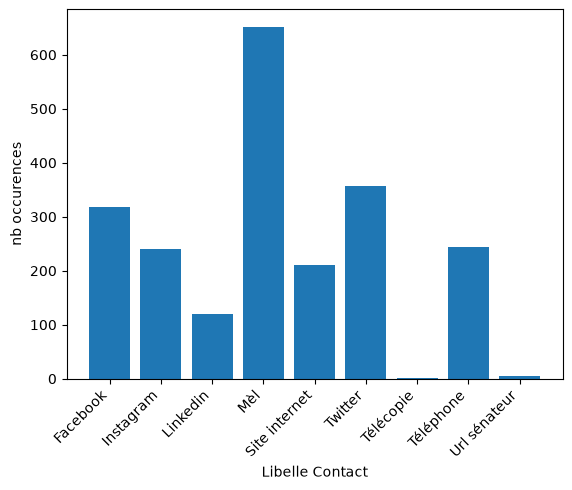

In [101]:
import matplotlib.pyplot as plt
#group by typeLybelle
plot_act_df = mail_act_df.groupby('typeLibelle').size().to_frame(name='count').reset_index()
categories_act = plot_act_df['typeLibelle']
values_act = plot_act_df['count']

plt.bar(categories_act, values_act)
plt.xlabel('Libelle Contact')
plt.ylabel('nb occurences')
plt.tick_params("x", rotation = 45, rotation_mode = "xtick")


plt.show()

In [102]:
mail_act_df[mail_act_df['typeLibelle'] == 'Url sénateur']

,uid,dataset,type,typeLibelle,poids,adresseDeRattachement,valElec,xsiType,acteurRefUid,dateMaj,datePremierAjout
689,AD317000,0,23,Url sénateur,NaN,NaN,https://www.senat.fr/senateur/letard_valerie01...,AdresseSiteWeb_Type,PA227089,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
1648,AD317086,0,23,Url sénateur,NaN,NaN,https://www.senat.fr/senateur/voynet_dominique...,AdresseSiteWeb_Type,PA2940,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
2232,AD317538,0,23,Url sénateur,NaN,NaN,https://www.senat.fr/senateur/barnier_michel95...,AdresseSiteWeb_Type,PA368,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
2498,AD703763,0,23,Url sénateur,NaN,NaN,https://www.senat.fr/senateur/bonnecarrere_phi...,AdresseSiteWeb_Type,PA569,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
5290,AD824361,0,23,Url sénateur,NaN,NaN,https://www.senat.fr/senateur/taille_polian_so...,AdresseSiteWeb_Type,PA736201,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z


Deputy with senateur Url are deputies who are former senateur

## Should we Create an Enriched Deputy Table with adresseMail table ?

In [ ]:
#we keep only the 'valElec' column (i.e. the column with the adress value) and filter on type 15 to have only mail adress type
mail_only_join = mail_df[mail_df['type'] == '15' ].drop(columns=[
    'uid',
    'dataset',
    'type',
    'typeLibelle',
    'poids',
    'adresseDeRattachement',
    'xsiType',
    'dateMaj',
    'datePremierAjout'
    ])

#join on 'acteurRefUid' of mail table and 'uid' of deputy table
tricoteuse_dep_enr = tricoteuse_dep.join(mail_only_join.set_index('acteurRefUid'), on='uid', how='left')

In [40]:
tricoteuse_dep_enr.rename(columns={'valElec': 'email'}, inplace=True)

tricoteuse_dep_enr.info()

<class 'pandas.DataFrame'>
Index: 652 entries, 0 to 595
Data columns (total 17 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   uid                                  652 non-null    str    
 1   nom                                  652 non-null    str    
 2   prenom                               652 non-null    str    
 3   civ                                  652 non-null    str    
 4   actif                                652 non-null    bool   
 5   compteTwitter                        413 non-null    str    
 6   compteBluesky                        195 non-null    str    
 7   groupeParlementaire.uid              652 non-null    str    
 8   groupeParlementaire.libelle          652 non-null    str    
 9   groupeParlementaire.libelleAbrege    652 non-null    str    
 10  groupeParlementaire.couleurAssociee  652 non-null    str    
 11  groupeParlementaire.chambre          652 non-nul

### Duplicated values after join : exploration

In [57]:
#number of occurences of deputy ids
tricoteuse_dep_enr['uid_occ'] = tricoteuse_dep_enr.groupby('uid')['uid'].transform('count')


In [ ]:
#check of the distinct values in uid_occ -> the deputies have max 2 occurences in the dataset, i.e. max 2 email adresses
tricoteuse_dep_enr['uid_occ'].unique()

array([1, 2])

In [52]:
#filter on uid_occ > 1
tricoteuse_dep_enr.query('uid_occ > 1')

,uid,nom,prenom,civ,actif,compteTwitter,compteBluesky,groupeParlementaire.uid,groupeParlementaire.libelle,groupeParlementaire.libelleAbrege,groupeParlementaire.couleurAssociee,groupeParlementaire.chambre,circonscription.uid,circonscription.numCirco,circonscription.numDepartement,circonscription.libelle,email,uid_occ
3,PA1592,Habib,David,M.,True,@DavidDhabib,wrenswatch.bsky.social,PO845485,"Libertés, Indépendants, Outre-mer et Territoires",LIOT,#CBA603,AN,PO839701,3.0,64.0,3ème circonscription des Pyrénées-Atlantiques,dhabib.jurancon@orange.fr,2
3,PA1592,Habib,David,M.,True,@DavidDhabib,wrenswatch.bsky.social,PO845485,"Libertés, Indépendants, Outre-mer et Territoires",LIOT,#CBA603,AN,PO839701,3.0,64.0,3ème circonscription des Pyrénées-Atlantiques,David.Habib@assemblee-nationale.fr,2
6,PA227089,Létard,Valérie,Mme,True,@valerieletard,NaN,PO845485,"Libertés, Indépendants, Outre-mer et Territoires",LIOT,#CBA603,AN,PO839601,21.0,59.0,21ème circonscription du Nord,valerie.letard@assemblee-nationale.fr,2
6,PA227089,Létard,Valérie,Mme,True,@valerieletard,NaN,PO845485,"Libertés, Indépendants, Outre-mer et Territoires",LIOT,#CBA603,AN,PO839601,21.0,59.0,21ème circonscription du Nord,cabinet@valerieletard.org,2
8,PA266797,Gosselin,Philippe,M.,True,@phgosselin,NaN,PO845425,Droite Républicaine,DR,#15A2A2,AN,PO839443,1.0,50.0,1ère circonscription de la Manche,philippe.gosselin@assemblee-nationale.fr,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
536,PA841665,Fégné,Denis,M.,True,NaN,NaN,PO845419,Socialistes et apparentés,SOC,#EC407A,AN,PO839705,2.0,65.0,2ème circonscription des Hautes-Pyrénées,permanencedenisfegne@gmail.com,2
541,PA841717,Runel,Sandrine,Mme,True,@SandrineRunel,sandrinerunel.bsky.social,PO845419,Socialistes et apparentés,SOC,#EC407A,AN,PO839725,4.0,69.0,4ème circonscription du Rhône,sandrine.runel@assemblee-nationale.fr,2
541,PA841717,Runel,Sandrine,Mme,True,@SandrineRunel,sandrinerunel.bsky.social,PO845419,Socialistes et apparentés,SOC,#EC407A,AN,PO839725,4.0,69.0,4ème circonscription du Rhône,sandrine.runel@mairie-lyon.fr,2
595,PA942,de Courson,Charles,M.,True,NaN,NaN,PO845485,"Libertés, Indépendants, Outre-mer et Territoires",LIOT,#CBA603,AN,PO839539,5.0,51.0,5ème circonscription de la Marne,charles.de-courson@wanadoo.fr,2


Pre-Conclusion : we have 156 rows after filtering with deputies with more than 1 occurence, meaning we have 156/2 = 78 deputies with 2 email adresses.

Next-Step, we will check if the couples of email adresses are an @assemblee-national.fr + an other domain

In [61]:
#filter on uid_occ > 1 and email like '%@assemblee-nationale.fr'
tricoteuse_dep_enr.query('uid_occ > 1 and email.str.contains("@assemblee-nationale.fr")') 

,uid,nom,prenom,civ,actif,compteTwitter,compteBluesky,groupeParlementaire.uid,groupeParlementaire.libelle,groupeParlementaire.libelleAbrege,groupeParlementaire.couleurAssociee,groupeParlementaire.chambre,circonscription.uid,circonscription.numCirco,circonscription.numDepartement,circonscription.libelle,email,uid_occ
3,PA1592,Habib,David,M.,True,@DavidDhabib,wrenswatch.bsky.social,PO845485,"Libertés, Indépendants, Outre-mer et Territoires",LIOT,#CBA603,AN,PO839701,3.0,64.0,3ème circonscription des Pyrénées-Atlantiques,David.Habib@assemblee-nationale.fr,2
6,PA227089,Létard,Valérie,Mme,True,@valerieletard,NaN,PO845485,"Libertés, Indépendants, Outre-mer et Territoires",LIOT,#CBA603,AN,PO839601,21.0,59.0,21ème circonscription du Nord,valerie.letard@assemblee-nationale.fr,2
8,PA266797,Gosselin,Philippe,M.,True,@phgosselin,NaN,PO845425,Droite Républicaine,DR,#15A2A2,AN,PO839443,1.0,50.0,1ère circonscription de la Manche,philippe.gosselin@assemblee-nationale.fr,2
9,PA266808,Rolland,Vincent,M.,True,NaN,NaN,PO845425,Droite Républicaine,DR,#15A2A2,AN,PO839779,2.0,73.0,2ème circonscription de la Savoie,Vincent.Rolland@assemblee-nationale.fr,2
10,PA267042,Favennec-Bécot,Yannick,M.,True,@yfavennec,NaN,PO845485,"Libertés, Indépendants, Outre-mer et Territoires",LIOT,#CBA603,AN,PO839507,3.0,53.0,3ème circonscription de la Mayenne,Yannick.Favennec@assemblee-nationale.fr,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,PA841495,Amblard,Maxime,M.,True,@MaximeAmblard5,NaN,PO845401,Rassemblement National,RN,#5C6BC0,AN,PO839571,1.0,55.0,1ère circonscription de la Meuse,maxime.amblard@assemblee-nationale.fr,2
525,PA841553,Tesson,Thierry,M.,True,NaN,NaN,PO845401,Rassemblement National,RN,#5C6BC0,AN,PO839593,17.0,59.0,17ème circonscription du Nord,thierry.tesson@assemblee-nationale.fr,2
536,PA841665,Fégné,Denis,M.,True,NaN,NaN,PO845419,Socialistes et apparentés,SOC,#EC407A,AN,PO839705,2.0,65.0,2ème circonscription des Hautes-Pyrénées,denis.fegne@assemblee-nationale.fr,2
541,PA841717,Runel,Sandrine,Mme,True,@SandrineRunel,sandrinerunel.bsky.social,PO845419,Socialistes et apparentés,SOC,#EC407A,AN,PO839725,4.0,69.0,4ème circonscription du Rhône,sandrine.runel@assemblee-nationale.fr,2


Half of the 156 rows with 2 occurences of uid have assemblee-national.fr domain. 

### Conclusion : les Tricoteuses have enriched the email adresses database with 78 email adresses. It is better to keep the contact table separated for now.

A solution to have only one table would be to pivot the typeLibelle column in the adresseElectronique table

## Email adresses check : has the tricoteuses made some changes on the datan data?

#### Get data from datan

In [68]:
#rid of the dataset imported from https://explore.data.gouv.fr/fr/datasets/5fc8b732d30fbf1ed6648aab/#/resources/092bd7bb-1543-405b-b53c-932ebb49bb8e
rid = "092bd7bb-1543-405b-b53c-932ebb49bb8e"

response_dn = requests.get(
    "https://tabular-api.data.gouv.fr/api/resources/" + rid + "/data/json/",
)

data_dn = response_dn.json()

datan_dep = pd.json_normalize(data_dn)

In [69]:
#we keep only the 'id' and 'mail' columns
datan_mail_only=datan_dep[['id','mail']]

KeyError: "None of [Index(['id', 'mail'], dtype='str')] are in the [columns]"

#### Filter data from tricoteuses to only keep mail with assemblee nationale domain

In [ ]:
#we keep only the 'uid' and 'mail' columns from tricoteuse_dep_enr and rename them to 'id' and 'mail'
tricoteuse_mail_only = tricoteuse_dep_enr.query('email.str.contains(("@assemblee-nationale.fr"))')[['uid','email']].rename(columns={'uid': 'id', 'email': 'mail'})
tricoteuse_mail_only.info()

<class 'pandas.DataFrame'>
Index: 574 entries, 0 to 595
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      574 non-null    str  
 1   mail    574 non-null    str  
dtypes: str(2)
memory usage: 39.5 KB


In [ ]:
#concatenate both table and drop duplicates
mail_compare = pd.concat([datan_mail_only, tricoteuse_mail_only]).drop_duplicates(keep=False)

In [ ]:
mail_compare.info()

<class 'pandas.DataFrame'>
Index: 0 entries
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      0 non-null      str  
 1   mail    0 non-null      str  
dtypes: str(2)
memory usage: 0.0 bytes


### Conclusion : the email adresses with @assemblee-national.fr domain are the same than the adresses from datan 

### Remaining question : are those emails all valid? -> validation email via SMTP?

## Contacts Info Table

we reuse the table we have created at the end of the data exploration section

Next Step : Drop useless columns and rename remaining columns

In [103]:
mail_act_df.head()

,uid,dataset,type,typeLibelle,poids,adresseDeRattachement,valElec,xsiType,acteurRefUid,dateMaj,datePremierAjout
8,AD726544,0,11,Téléphone,22,AD726542,07 88 44 06 75,AdresseTelephonique_Type,PA1008,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
9,AD768593,0,22,Site internet,NaN,NaN,alain-david.com,AdresseSiteWeb_Type,PA1008,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
10,AD799407,0,15,Mèl,NaN,NaN,Alain.David@assemblee-nationale.fr,AdresseMail_Type,PA1008,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
298,AD677287,0,15,Mèl,NaN,NaN,jerome.guedj@assemblee-nationale.fr,AdresseMail_Type,PA1567,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
299,AD798507,0,24,Twitter,NaN,NaN,@JeromeGuedj,AdresseSiteWeb_Type,PA1567,2026-10-27T11:54:58.077Z,2026-10-27T11:54:58.077Z
